# 11 — DINOv2 Series-Attention Multiple Instance Learning (MIL)

This notebook builds a **series-attention MIL baseline** from the frozen DINOv2 ViT-S/14 embeddings generated in Notebook 09.

The representation is constructed in two steps:

1. **Within each MRI series:** mean-pool the DINOv2 embeddings of its 2.5D instances to obtain one 384-dimensional series representation. This is a fixed, non-learned aggregation.
2. **Across the series in a study:** learn gated-attention weights over the variable number of series, aggregate them into a study representation, and predict the 12 study-level abnormalities.

The learned attention in this notebook is therefore **over MRI series**, not over individual slices. Notebook 10 is the flat slice-attention baseline; Notebook 12 is reserved for the full hierarchical slice-attention → series-attention model.

## Evaluation protocol

- 58 studies with complete structured labels.
- The same five study-level folds saved in Notebook 09 / Notebook 05.
- Inner validation split within each outer-training fold to select the epoch count.
- Reinitialize and refit on the complete outer-training fold for the selected epoch count.
- Evaluate the untouched outer held-out fold only after refitting.
- Fixed classification threshold: 0.50.
- Weighted binary cross-entropy, using positive weights calculated only from the relevant training subset.

**Important:** This is a gold-label baseline. The report-based weak-supervision teacher is not used in this notebook.

## 1. Imports and experiment configuration

In [1]:
import os
import gc
import json
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    f1_score,
    precision_score,
    recall_score,
    hamming_loss,
    accuracy_score,
)

warnings.filterwarnings("ignore")

SEED = 42
N_FOLDS = 5
EXPECTED_GOLD_STUDIES = 58
NUM_CLASSES = 12
EMBED_DIM = 384
CLASSIFICATION_THRESHOLD = 0.50

# The embeddings are frozen features from Notebook 09. Only the MIL attention
# module and study-level classifier are trained here.
EPOCHS = 50
PATIENCE = 10
ATTENTION_DIM = 128
HIDDEN_DIM = 128
DROPOUT = 0.25
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
MAX_GRAD_NORM = 1.0

OUTPUT_DIR = "/kaggle/working"
os.makedirs(OUTPUT_DIR, exist_ok=True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

LABEL_COLS = [
    "ACL",
    "MCL",
    "Medial Meniscus",
    "Lateral Meniscus",
    "Medial OA",
    "Lateral OA",
    "PF OA",
    "Effusion",
    "Synovitis",
    "Baker's",
    "Contusion",
    "Fracture",
]


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_seed(SEED)
print("Device:", DEVICE)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
print("Number of target findings:", len(LABEL_COLS))
print("Classification threshold:", CLASSIFICATION_THRESHOLD)
print("Output directory:", OUTPUT_DIR)

Device: cuda
GPU: Tesla T4
Number of target findings: 12
Classification threshold: 0.5
Output directory: /kaggle/working


## 2. Locate the competition data and Notebook 09 artifacts

### Required Kaggle inputs

1. **RSNA Knee Abnormality Detection competition dataset**, containing `train.csv` with the 12 structured labels.
2. **Saved output of Notebook 09**, containing:
   - `dinov2_vits14_embeddings_float16.npy`
   - `dinov2_vits14_embedding_metadata.csv`
   - `dinov2_vits14_embedding_manifest.json` (recommended)
   - `dinov2_vits14_coverage_summary.csv` (recommended)

Attach Notebook 09 through Kaggle **Add Input → Notebook Output**. Raw DICOM files and the outputs of Notebooks 03, 04 and 05 are not required directly by Notebook 11 because the embeddings metadata already carries the study, series and fold identifiers.

Notebook 07, 08 and 10 comparison-row CSVs are optional and are used only in the final comparison cell.

In [2]:
SEARCH_ROOTS = ["/kaggle/input", "/kaggle/working"]
PRUNE_DIRS = {
    "train_images", "test_images", "train_series", "test_series",
    "processed_data", "__pycache__", ".git", ".ipynb_checkpoints"
}


def find_all_files(filename):
    matches = []
    for base in SEARCH_ROOTS:
        if not os.path.exists(base):
            continue
        for current, dirs, files in os.walk(base):
            dirs[:] = [d for d in dirs if d not in PRUNE_DIRS]
            if filename in files:
                matches.append(os.path.join(current, filename))
    return sorted(set(matches))


def choose_file(filename, preferred_tokens=(), required=True):
    candidates = find_all_files(filename)
    if not candidates:
        if required:
            raise FileNotFoundError(
                f"Could not find {filename}. Attach the RSNA competition dataset "
                "and the saved output of Notebook 09 using Kaggle Add Input."
            )
        return None

    preferred = []
    for token in preferred_tokens:
        preferred = [p for p in candidates if token.lower() in p.lower()]
        if preferred:
            break

    chosen_pool = preferred if preferred else candidates
    if len(chosen_pool) > 1:
        print(f"Multiple candidates found for {filename}; selected the first preferred path:")
        for candidate in chosen_pool[:8]:
            print("  ", candidate)
    return chosen_pool[0]


TRAIN_CSV_PATH = choose_file(
    "train.csv",
    preferred_tokens=("competitions/rsna", "rsna-knee-abnormality-detection", "rsna-knee"),
)
EMBEDDING_PATH = choose_file(
    "dinov2_vits14_embeddings_float16.npy",
    preferred_tokens=("09-dinov2", "dinov2"),
)
METADATA_PATH = choose_file(
    "dinov2_vits14_embedding_metadata.csv",
    preferred_tokens=("09-dinov2", "dinov2"),
)
MANIFEST_PATH = choose_file(
    "dinov2_vits14_embedding_manifest.json",
    preferred_tokens=("09-dinov2", "dinov2"),
    required=False,
)
COVERAGE_PATH = choose_file(
    "dinov2_vits14_coverage_summary.csv",
    preferred_tokens=("09-dinov2", "dinov2"),
    required=False,
)

print("Competition train.csv:", TRAIN_CSV_PATH)
print("DINOv2 embeddings:", EMBEDDING_PATH)
print("Embedding metadata:", METADATA_PATH)
print("Manifest:", MANIFEST_PATH or "not attached (optional)")
print("Coverage summary:", COVERAGE_PATH or "not attached (optional)")

Competition train.csv: /kaggle/input/competitions/rsna-knee-abnormality-detection/train.csv
DINOv2 embeddings: /kaggle/input/notebooks/minnieg12/09-dinov2/dinov2_vits14_embeddings_float16.npy
Embedding metadata: /kaggle/input/notebooks/minnieg12/09-dinov2/dinov2_vits14_embedding_metadata.csv
Manifest: /kaggle/input/notebooks/minnieg12/09-dinov2/dinov2_vits14_embedding_manifest.json
Coverage summary: /kaggle/input/notebooks/minnieg12/09-dinov2/dinov2_vits14_coverage_summary.csv


## 3. Load Notebook 09 artifacts and validate embedding integrity

In [3]:
if MANIFEST_PATH:
    with open(MANIFEST_PATH, "r", encoding="utf-8") as f:
        embedding_manifest = json.load(f)
    print("Notebook 09 manifest:", embedding_manifest)

    if embedding_manifest.get("smoke_test") is True:
        raise RuntimeError(
            "The attached Notebook 09 output is marked as a smoke test. "
            "Rerun Notebook 09 with SMOKE_TEST=False and DATA_SCOPE='gold', "
            "save a new version, and attach that output."
        )
    if embedding_manifest.get("data_scope", "gold") != "gold":
        raise RuntimeError(
            "Notebook 11 expects the Notebook 09 DATA_SCOPE='gold' output."
        )
else:
    embedding_manifest = {}

train = pd.read_csv(TRAIN_CSV_PATH)
metadata = pd.read_csv(METADATA_PATH)
embeddings_memmap = np.load(EMBEDDING_PATH, mmap_mode="r")

print("Competition train rows:", len(train))
print("Embedding array shape:", embeddings_memmap.shape)
print("Metadata shape:", metadata.shape)

required_metadata_cols = [
    "Embedding_Index", "StudyInstanceUID", "SeriesInstanceUID", "fold"
]
missing_metadata_cols = [c for c in required_metadata_cols if c not in metadata.columns]
if missing_metadata_cols:
    raise ValueError(
        "Notebook 09 metadata is missing required columns: "
        + str(missing_metadata_cols)
    )
missing_label_cols = [c for c in ["StudyInstanceUID"] + LABEL_COLS if c not in train.columns]
if missing_label_cols:
    raise ValueError("Competition train.csv is missing columns: " + str(missing_label_cols))

if embeddings_memmap.ndim != 2:
    raise ValueError(
        f"Expected [2.5D instances, features] embeddings, got {embeddings_memmap.shape}."
    )
if embeddings_memmap.shape[1] != EMBED_DIM:
    raise ValueError(
        f"Expected {EMBED_DIM}-dimensional DINOv2 vectors, got {embeddings_memmap.shape[1]}."
    )
if len(metadata) != embeddings_memmap.shape[0]:
    raise ValueError(
        f"Embedding/metadata row mismatch: {embeddings_memmap.shape[0]} vectors "
        f"versus {len(metadata)} metadata rows."
    )

metadata["Embedding_Index"] = pd.to_numeric(
    metadata["Embedding_Index"], errors="raise"
).astype(int)
metadata["fold"] = pd.to_numeric(metadata["fold"], errors="raise").astype(int)
metadata["StudyInstanceUID"] = metadata["StudyInstanceUID"].astype(str)
metadata["SeriesInstanceUID"] = metadata["SeriesInstanceUID"].astype(str)
metadata = metadata.sort_values("Embedding_Index").reset_index(drop=True)

expected_indices = np.arange(len(metadata), dtype=int)
if not np.array_equal(metadata["Embedding_Index"].to_numpy(), expected_indices):
    raise ValueError(
        "Embedding_Index must be unique and contiguous from 0 to N-1, "
        "so metadata rows align with embedding-array rows. Rerun Notebook 09 if needed."
    )
if metadata["Embedding_Index"].duplicated().any():
    raise ValueError("Duplicate Embedding_Index values found.")

embeddings = np.asarray(embeddings_memmap, dtype=np.float32)
del embeddings_memmap
if not np.isfinite(embeddings).all():
    raise ValueError("Non-finite values detected in DINOv2 embeddings.")

print("Loaded embeddings as float32:", embeddings.shape)
print("Embedding/metadata alignment: PASSED")
print("Finite embeddings: PASSED")

Notebook 09 manifest: {'model_name': 'hf_hub:timm/vit_small_patch14_dinov2.lvd142m', 'embedding_dim': 384, 'input_size': [3, 518, 518], 'source_size': [3, 224, 224], 'data_scope': 'gold', 'smoke_test': False, 'num_studies': 58, 'num_embeddings': 10528, 'dtype': 'float16', 'seed': 42}
Competition train rows: 4407
Embedding array shape: (10528, 384)
Metadata shape: (10528, 12)
Loaded embeddings as float32: (10528, 384)
Embedding/metadata alignment: PASSED
Finite embeddings: PASSED


## 4. Join gold labels and validate study-level folds

The fold values are read from Notebook 09 metadata, which carries the study-level assignments created in Notebook 05. This notebook does not create new folds.

In [4]:
train["StudyInstanceUID"] = train["StudyInstanceUID"].astype(str)
for col in LABEL_COLS:
    train[col] = pd.to_numeric(train[col], errors="coerce")

gold_df = train.dropna(subset=LABEL_COLS).copy()
if gold_df["StudyInstanceUID"].duplicated().any():
    raise ValueError("Duplicate StudyInstanceUID rows in competition train.csv.")

fold_nunique = metadata.groupby("StudyInstanceUID")["fold"].nunique()
if not (fold_nunique == 1).all():
    bad = fold_nunique[fold_nunique != 1].index.tolist()[:10]
    raise ValueError(f"Fold assignment is not unique per study. Example IDs: {bad}")

fold_map = metadata[["StudyInstanceUID", "fold"]].drop_duplicates().copy()
gold_df = gold_df.merge(
    fold_map, on="StudyInstanceUID", how="inner", validate="one_to_one"
)

metadata_studies = set(metadata["StudyInstanceUID"].unique())
gold_studies = set(gold_df["StudyInstanceUID"].unique())
missing_from_embeddings = sorted(gold_studies - metadata_studies)
extra_in_embeddings = sorted(metadata_studies - gold_studies)

print("Complete gold-labelled studies in train.csv:", len(train.dropna(subset=LABEL_COLS)))
print("Gold studies represented in embeddings:", len(gold_studies))
print("Study fold counts:")
print(gold_df["fold"].value_counts().sort_index())
print("2.5D instances:", len(metadata))
print("MRI series:", metadata[["StudyInstanceUID", "SeriesInstanceUID"]].drop_duplicates().shape[0])

if missing_from_embeddings or extra_in_embeddings:
    raise ValueError(
        "Gold-label/embedding study coverage mismatch. "
        f"Missing (first 5): {missing_from_embeddings[:5]}; "
        f"extra (first 5): {extra_in_embeddings[:5]}. "
        "Attach the complete 58-study gold output from Notebook 09."
    )
if len(gold_df) != EXPECTED_GOLD_STUDIES:
    raise ValueError(
        f"Expected {EXPECTED_GOLD_STUDIES} fully labelled studies, found {len(gold_df)}."
    )
if set(gold_df["fold"].unique()) != set(range(N_FOLDS)):
    raise ValueError(
        f"Expected fold IDs 0..{N_FOLDS-1}, found {sorted(gold_df['fold'].unique())}."
    )
if not gold_df[LABEL_COLS].isin([0, 1]).all().all():
    raise ValueError("Gold labels must contain only binary 0/1 values.")
if not (gold_df["fold"].value_counts().sort_index().to_numpy() == np.array([12, 12, 12, 11, 11])).all():
    raise ValueError("Unexpected fold sizes. Confirm the unchanged Notebook 05 study-level split.")

gold_df = gold_df.sort_values(["fold", "StudyInstanceUID"]).reset_index(drop=True)
LABEL_BY_STUDY = {
    row["StudyInstanceUID"]: row[LABEL_COLS].to_numpy(dtype=np.float32)
    for _, row in gold_df.iterrows()
}
FOLD_BY_STUDY = dict(zip(gold_df["StudyInstanceUID"], gold_df["fold"].astype(int)))
STUDY_IDS = sorted(gold_df["StudyInstanceUID"].tolist())

print("Gold-label coverage and original folds: PASSED")
display(gold_df[["StudyInstanceUID", "fold"] + LABEL_COLS].head())

Complete gold-labelled studies in train.csv: 58
Gold studies represented in embeddings: 58
Study fold counts:
fold
0    12
1    12
2    12
3    11
4    11
Name: count, dtype: int64
2.5D instances: 10528
MRI series: 336
Gold-label coverage and original folds: PASSED


,StudyInstanceUID,fold,ACL,MCL,Medial Meniscus,Lateral Meniscus,Medial OA,Lateral OA,PF OA,Effusion,Synovitis,Baker's,Contusion,Fracture
0,1.2.826.0.1.3680043.8.498.10095687747295410396...,0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0
1,1.2.826.0.1.3680043.8.498.11287937729196958426...,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
2,1.2.826.0.1.3680043.8.498.11548045715264151632...,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0
3,1.2.826.0.1.3680043.8.498.12606657226568558340...,0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,1.2.826.0.1.3680043.8.498.12801308844398614687...,0,0.0,0.0,1.0,1.0,1.0,0.0,0.0,1.0,1.0,1.0,1.0,0.0


## 5. Aggregate DINOv2 instance embeddings into MRI-series embeddings

For each `(StudyInstanceUID, SeriesInstanceUID)` pair, this cell computes the arithmetic mean of all 2.5D-instance embeddings belonging to that series. This makes one 384-dimensional vector per MRI series. The aggregation is deterministic and does not use labels.

The resulting study bag contains a variable number of series. The learned attention module in the next section assigns weights across those series.

In [5]:
series_records = []
series_feature_rows = []
optional_series_columns = [
    "Anatomical_Plane", "Fluid_Sensitive", "Fat_Suppression", "Num_Slices"
]

for (study_id, series_id), group in metadata.groupby(
    ["StudyInstanceUID", "SeriesInstanceUID"], sort=True
):
    group = group.sort_values("Embedding_Index")
    folds = group["fold"].unique()
    if len(folds) != 1:
        raise ValueError(
            f"Series {series_id} in study {study_id} has multiple fold assignments."
        )

    embedding_indices = group["Embedding_Index"].to_numpy(dtype=np.int64)
    if len(embedding_indices) == 0:
        raise RuntimeError(f"Empty series encountered: {study_id} / {series_id}.")

    # One fixed mean-pooled vector for this MRI series.
    series_vector = embeddings[embedding_indices].mean(axis=0, dtype=np.float32)
    if not np.isfinite(series_vector).all():
        raise RuntimeError(f"Non-finite pooled series vector: {study_id} / {series_id}.")

    record = {
        "Series_Index": len(series_records),
        "StudyInstanceUID": str(study_id),
        "SeriesInstanceUID": str(series_id),
        "fold": int(folds[0]),
        "Num_2p5D_Instances": int(len(embedding_indices)),
    }
    for col in optional_series_columns:
        if col in group.columns:
            values = group[col].dropna()
            record[col] = values.iloc[0] if len(values) else np.nan

    series_records.append(record)
    series_feature_rows.append(series_vector)

series_metadata = pd.DataFrame(series_records)
series_embeddings = np.stack(series_feature_rows).astype(np.float32)

if series_metadata.empty:
    raise RuntimeError("No series embeddings were created.")
if series_embeddings.shape != (len(series_metadata), EMBED_DIM):
    raise RuntimeError(
        f"Unexpected series embedding shape {series_embeddings.shape}; "
        f"metadata rows={len(series_metadata)}."
    )
if series_metadata["Series_Index"].duplicated().any():
    raise RuntimeError("Duplicate Series_Index values found.")
if series_metadata.duplicated(["StudyInstanceUID", "SeriesInstanceUID"]).any():
    raise RuntimeError("A study/series pair appears more than once.")
if not np.isfinite(series_embeddings).all():
    raise RuntimeError("Non-finite pooled series embeddings detected.")

# Build study -> series-index bags. Indices align with rows of series_embeddings.
STUDY_SERIES_INDICES = {}
SERIES_METADATA = {}
for study_id, group in series_metadata.groupby("StudyInstanceUID", sort=False):
    group = group.sort_values("Series_Index").reset_index(drop=True)
    STUDY_SERIES_INDICES[study_id] = group["Series_Index"].to_numpy(dtype=np.int64)
    SERIES_METADATA[study_id] = group

if set(STUDY_SERIES_INDICES) != set(STUDY_IDS):
    raise RuntimeError("Study-to-series bags do not cover exactly the 58 gold studies.")
if any(len(indices) == 0 for indices in STUDY_SERIES_INDICES.values()):
    raise RuntimeError("At least one study has no MRI series.")
if int(series_metadata["Num_2p5D_Instances"].sum()) != len(metadata):
    raise RuntimeError("Series aggregation did not account for every 2.5D embedding row.")

SERIES_EMBEDDINGS_TENSOR = torch.as_tensor(
    series_embeddings, dtype=torch.float32, device=DEVICE
)
INPUT_DIM = int(series_embeddings.shape[1])

print("2.5D-instance embeddings:", embeddings.shape)
print("Pooled MRI-series embeddings:", series_embeddings.shape)
print("Studies with series bags:", len(STUDY_SERIES_INDICES))
print("Total MRI series:", len(series_metadata))
print("Instances accounted for by series pooling:", int(series_metadata["Num_2p5D_Instances"].sum()))
print("Series per study (descriptive statistics):")
display(series_metadata.groupby("StudyInstanceUID").size().describe().to_frame("series_per_study"))
print("Series embedding and metadata alignment: PASSED")

2.5D-instance embeddings: (10528, 384)
Pooled MRI-series embeddings: (336, 384)
Studies with series bags: 58
Total MRI series: 336
Instances accounted for by series pooling: 10528
Series per study (descriptive statistics):


,series_per_study
count,58.000000
mean,5.793103
std,1.460096
min,4.000000
25%,5.000000
50%,5.000000
75%,6.000000
max,9.000000


Series embedding and metadata alignment: PASSED


## 6. Define gated series-attention MIL

Each series is represented by its mean-pooled DINOv2 vector. Gated attention produces one normalized weight per series within a study. The weighted sum is passed to the 12-output classifier.

In [6]:
class GatedSeriesAttentionMIL(nn.Module):
    """Gated attention pooling over MRI-series embeddings within one study."""
    def __init__(
        self,
        input_dim=EMBED_DIM,
        attention_dim=ATTENTION_DIM,
        hidden_dim=HIDDEN_DIM,
        num_classes=NUM_CLASSES,
        dropout=DROPOUT,
    ):
        super().__init__()
        self.series_norm = nn.LayerNorm(input_dim)
        self.attention_v = nn.Linear(input_dim, attention_dim)
        self.attention_u = nn.Linear(input_dim, attention_dim)
        self.attention_w = nn.Linear(attention_dim, 1, bias=False)
        self.classifier = nn.Sequential(
            nn.LayerNorm(input_dim),
            nn.Linear(input_dim, hidden_dim),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, num_classes),
        )

    def forward(self, series_embeddings, return_attention=False):
        if series_embeddings.ndim != 2 or series_embeddings.shape[0] == 0:
            raise ValueError("Expected a non-empty [series, features] study bag.")
        x = self.series_norm(series_embeddings)
        gated = torch.tanh(self.attention_v(x)) * torch.sigmoid(self.attention_u(x))
        attention_logits = self.attention_w(gated).squeeze(-1)
        attention_weights = torch.softmax(attention_logits, dim=0)
        study_embedding = torch.sum(attention_weights.unsqueeze(-1) * x, dim=0)
        logits = self.classifier(study_embedding)
        if return_attention:
            return logits, attention_weights
        return logits


def create_pos_weight(train_study_ids):
    y = np.stack([LABEL_BY_STUDY[sid] for sid in train_study_ids]).astype(np.float32)
    positives = y.sum(axis=0)
    negatives = len(y) - positives
    weights = np.ones(NUM_CLASSES, dtype=np.float32)
    valid = positives > 0
    weights[valid] = negatives[valid] / positives[valid]
    weights = np.clip(weights, 1.0, 20.0)
    return torch.tensor(weights, dtype=torch.float32, device=DEVICE)


print("Series-attention MIL model ready.")
print("Input dimension:", INPUT_DIM)
print("Attention dimension:", ATTENTION_DIM)
print("Output labels:", NUM_CLASSES)

# Small shape/normalization smoke test before cross-validation.
_smoke_model = GatedSeriesAttentionMIL().to(DEVICE)
_smoke_input = torch.as_tensor(
    series_embeddings[:min(3, len(series_embeddings))],
    dtype=torch.float32,
    device=DEVICE,
)
_smoke_logits, _smoke_weights = _smoke_model(_smoke_input, return_attention=True)
assert tuple(_smoke_logits.shape) == (NUM_CLASSES,)
assert torch.isfinite(_smoke_logits).all()
assert torch.allclose(_smoke_weights.sum(), torch.tensor(1.0, device=DEVICE), atol=1e-6)
print("Forward-pass and attention-normalization smoke test: PASSED")
del _smoke_model, _smoke_input, _smoke_logits, _smoke_weights

Series-attention MIL model ready.
Input dimension: 384
Attention dimension: 128
Output labels: 12
Forward-pass and attention-normalization smoke test: PASSED


## 7. Evaluation utilities

Metrics use the fixed threshold of 0.50. ROC-AUC and average precision are recorded as `NaN` for a finding when the evaluated set contains only one class.

In [7]:
def compute_per_class_metrics(y_true, y_prob, threshold=CLASSIFICATION_THRESHOLD):
    y_true = np.asarray(y_true).astype(int)
    y_prob = np.asarray(y_prob).astype(float)
    y_pred = (y_prob >= threshold).astype(int)
    rows = []

    for j, label in enumerate(LABEL_COLS):
        true_j = y_true[:, j]
        prob_j = y_prob[:, j]
        pred_j = y_pred[:, j]
        tp = int(np.sum((true_j == 1) & (pred_j == 1)))
        tn = int(np.sum((true_j == 0) & (pred_j == 0)))
        fp = int(np.sum((true_j == 0) & (pred_j == 1)))
        fn = int(np.sum((true_j == 1) & (pred_j == 0)))
        precision = tp / (tp + fp) if (tp + fp) else np.nan
        recall = tp / (tp + fn) if (tp + fn) else np.nan
        specificity = tn / (tn + fp) if (tn + fp) else np.nan
        f1 = (
            2 * precision * recall / (precision + recall)
            if np.isfinite(precision) and np.isfinite(recall) and (precision + recall) > 0
            else 0.0
        )
        auc = roc_auc_score(true_j, prob_j) if len(np.unique(true_j)) == 2 else np.nan
        pr_auc = average_precision_score(true_j, prob_j) if len(np.unique(true_j)) == 2 else np.nan
        rows.append({
            "label": label,
            "prevalence": float(true_j.mean()),
            "positive_count": int(true_j.sum()),
            "precision": precision,
            "recall": recall,
            "sensitivity": recall,
            "specificity": specificity,
            "f1": f1,
            "roc_auc": auc,
            "pr_auc": pr_auc,
            "tp": tp, "tn": tn, "fp": fp, "fn": fn,
        })
    return pd.DataFrame(rows)


def compute_metrics(y_true, y_prob, threshold=CLASSIFICATION_THRESHOLD):
    y_true = np.asarray(y_true).astype(int)
    y_prob = np.asarray(y_prob).astype(float)
    y_pred = (y_prob >= threshold).astype(int)
    per_class = compute_per_class_metrics(y_true, y_prob, threshold)
    valid_auc = per_class["roc_auc"].dropna()
    valid_pr = per_class["pr_auc"].dropna()
    return {
        "macro_auc": float(valid_auc.mean()) if len(valid_auc) else np.nan,
        "macro_pr_auc": float(valid_pr.mean()) if len(valid_pr) else np.nan,
        "macro_precision": float(precision_score(y_true, y_pred, average="macro", zero_division=0)),
        "macro_recall": float(recall_score(y_true, y_pred, average="macro", zero_division=0)),
        "macro_f1": float(f1_score(y_true, y_pred, average="macro", zero_division=0)),
        "macro_specificity": float(per_class["specificity"].mean()),
        "micro_f1": float(f1_score(y_true, y_pred, average="micro", zero_division=0)),
        "hamming_loss": float(hamming_loss(y_true, y_pred)),
        "subset_accuracy": float(accuracy_score(y_true, y_pred)),
        "valid_auc_classes": int(len(valid_auc)),
        "valid_pr_auc_classes": int(len(valid_pr)),
    }


def evaluate_studies(model, study_ids, criterion, collect_attention=False, fold=None):
    model.eval()
    losses, truths, probabilities = [], [], []
    attention_records = []

    with torch.no_grad():
        for study_id in study_ids:
            series_idx = STUDY_SERIES_INDICES[study_id]
            bag = SERIES_EMBEDDINGS_TENSOR[
                torch.as_tensor(series_idx, dtype=torch.long, device=DEVICE)
            ]
            y_np = LABEL_BY_STUDY[study_id]
            y_tensor = torch.as_tensor(y_np, dtype=torch.float32, device=DEVICE)

            if collect_attention:
                logits, weights = model(bag, return_attention=True)
                weights_np = weights.detach().cpu().numpy()
                meta_group = SERIES_METADATA[study_id]
                if len(meta_group) != len(weights_np):
                    raise RuntimeError(
                        f"Series-attention/metadata length mismatch for study {study_id}."
                    )
                meta_records = meta_group.to_dict(orient="records")
                for meta_row, weight in zip(meta_records, weights_np):
                    meta_row["fold"] = int(fold)
                    meta_row["attention_weight"] = float(weight)
                    attention_records.append(meta_row)
            else:
                logits = model(bag)

            loss = criterion(logits.unsqueeze(0), y_tensor.unsqueeze(0))
            losses.append(float(loss.item()))
            truths.append(y_np)
            probabilities.append(torch.sigmoid(logits).detach().cpu().numpy())

    return {
        "loss": float(np.mean(losses)) if losses else np.nan,
        "y_true": np.stack(truths),
        "y_prob": np.stack(probabilities),
        "attention_records": attention_records,
    }


print("Metrics and study-level evaluation functions ready.")

Metrics and study-level evaluation functions ready.


## 8. Train one outer fold with inner-split epoch selection

Epoch selection uses only the inner validation studies. The outer held-out fold is evaluated only after the model has been reinitialized and refitted on the complete outer-training fold.

In [8]:
def train_one_fold(fold):
    """Select epoch on an inner split; evaluate the outer fold after refitting."""
    outer_train_ids = sorted(s for s in STUDY_IDS if FOLD_BY_STUDY[s] != fold)
    outer_val_ids = sorted(s for s in STUDY_IDS if FOLD_BY_STUDY[s] == fold)
    if not outer_train_ids or not outer_val_ids:
        raise RuntimeError(f"Fold {fold} has an empty outer split.")

    split_rng = np.random.RandomState(SEED + 1000 + int(fold))
    shuffled = list(split_rng.permutation(np.asarray(outer_train_ids, dtype=object)))
    n_inner_val = max(1, int(round(0.20 * len(shuffled))))
    inner_val_ids = sorted(shuffled[:n_inner_val])
    inner_train_ids = sorted(shuffled[n_inner_val:])
    if len(inner_train_ids) < 2 or not inner_val_ids:
        raise RuntimeError(f"Invalid inner split for fold {fold}.")

    def make_model():
        return GatedSeriesAttentionMIL(
            input_dim=INPUT_DIM,
            attention_dim=ATTENTION_DIM,
            hidden_dim=HIDDEN_DIM,
            num_classes=NUM_CLASSES,
            dropout=DROPOUT,
        ).to(DEVICE)

    def train_epoch(model, fit_ids, criterion, optimizer, epoch, seed_offset):
        model.train()
        rng = np.random.RandomState(
            SEED + int(fold) * 1000 + seed_offset + epoch
        )
        losses = []
        for study_id in rng.permutation(np.asarray(fit_ids, dtype=object)):
            series_idx = STUDY_SERIES_INDICES[study_id]
            bag = SERIES_EMBEDDINGS_TENSOR[
                torch.as_tensor(series_idx, dtype=torch.long, device=DEVICE)
            ]
            y = torch.as_tensor(
                LABEL_BY_STUDY[study_id], dtype=torch.float32, device=DEVICE
            )
            optimizer.zero_grad(set_to_none=True)
            loss = criterion(model(bag).unsqueeze(0), y.unsqueeze(0))
            if not torch.isfinite(loss):
                raise RuntimeError(f"Non-finite loss: fold={fold}, epoch={epoch}.")
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), MAX_GRAD_NORM)
            optimizer.step()
            losses.append(float(loss.item()))
        return float(np.mean(losses))

    print("=" * 72)
    print(
        f"Fold {fold}: outer train={len(outer_train_ids)}, "
        f"outer held-out={len(outer_val_ids)}"
    )
    print(
        f"Inner epoch-selection split: train={len(inner_train_ids)}, "
        f"validation={len(inner_val_ids)}"
    )

    # Phase A — select the epoch count using only the inner split.
    set_seed(SEED + int(fold))
    selection_model = make_model()
    selection_criterion = nn.BCEWithLogitsLoss(
        pos_weight=create_pos_weight(inner_train_ids)
    )
    selection_optimizer = torch.optim.AdamW(
        selection_model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY
    )

    best_inner_val_loss = np.inf
    selected_epoch = None
    no_improvement = 0
    history_rows = []

    for epoch in range(1, EPOCHS + 1):
        train_loss = train_epoch(
            selection_model, inner_train_ids, selection_criterion,
            selection_optimizer, epoch, seed_offset=0,
        )
        inner_out = evaluate_studies(
            selection_model, inner_val_ids, selection_criterion,
            collect_attention=False,
        )
        inner_val_loss = float(inner_out["loss"])
        if not np.isfinite(inner_val_loss):
            raise RuntimeError(
                f"Non-finite inner-validation loss in fold {fold}, epoch {epoch}."
            )
        inner_metrics = compute_metrics(inner_out["y_true"], inner_out["y_prob"])
        history_rows.append({
            "fold": int(fold),
            "epoch": int(epoch),
            "stage": "inner_epoch_selection",
            "train_loss": train_loss,
            "val_loss": inner_val_loss,
            "val_macro_auc": inner_metrics["macro_auc"],
            "val_macro_pr_auc": inner_metrics["macro_pr_auc"],
            "val_macro_f1": inner_metrics["macro_f1"],
            "val_micro_f1": inner_metrics["micro_f1"],
        })

        if inner_val_loss < best_inner_val_loss - 1e-6:
            best_inner_val_loss = inner_val_loss
            selected_epoch = int(epoch)
            no_improvement = 0
        else:
            no_improvement += 1

        print(
            f"Fold {fold} | selection epoch {epoch:02d}/{EPOCHS} | "
            f"train={train_loss:.4f} | inner-val={inner_val_loss:.4f}"
        )
        if no_improvement >= PATIENCE:
            print(f"Inner early stopping after {PATIENCE} non-improving epochs.")
            break

    if selected_epoch is None:
        raise RuntimeError(f"No epoch selected for fold {fold}.")

    del selection_model, selection_optimizer, selection_criterion
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    # Phase B — reinitialize and refit on every outer-training study.
    set_seed(SEED + 10000 + int(fold))
    model = make_model()
    outer_criterion = nn.BCEWithLogitsLoss(
        pos_weight=create_pos_weight(outer_train_ids)
    )
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY
    )

    for epoch in range(1, selected_epoch + 1):
        loss = train_epoch(
            model, outer_train_ids, outer_criterion,
            optimizer, epoch, seed_offset=50000,
        )
        print(
            f"Fold {fold} | outer refit epoch {epoch:02d}/{selected_epoch} "
            f"| loss={loss:.4f}"
        )

    # Phase C — evaluate the untouched outer fold after all choices are fixed.
    final_val = evaluate_studies(
        model, outer_val_ids, outer_criterion,
        collect_attention=True, fold=fold,
    )
    final_metrics = compute_metrics(final_val["y_true"], final_val["y_prob"])

    checkpoint_path = os.path.join(
        OUTPUT_DIR, f"dinov2_series_attention_fold_{fold}.pth"
    )
    torch.save({
        "fold": int(fold),
        "model_state_dict": model.state_dict(),
        "input_dim": INPUT_DIM,
        "attention_dim": ATTENTION_DIM,
        "hidden_dim": HIDDEN_DIM,
        "num_classes": NUM_CLASSES,
        "label_cols": LABEL_COLS,
        "threshold": CLASSIFICATION_THRESHOLD,
        "selected_epoch": int(selected_epoch),
        "inner_best_val_loss": float(best_inner_val_loss),
        "inner_train_studies": list(inner_train_ids),
        "inner_val_studies": list(inner_val_ids),
        "outer_train_studies": list(outer_train_ids),
        "outer_heldout_studies": list(outer_val_ids),
        "aggregation": "mean 2.5D-instance embeddings within each series",
        "evaluation_protocol": "inner split selects epoch; outer held-out fold evaluated after refit",
    }, checkpoint_path)

    fold_result = {
        "fold": int(fold),
        "n_train_studies": len(outer_train_ids),
        "n_val_studies": len(outer_val_ids),
        "n_inner_train_studies": len(inner_train_ids),
        "n_inner_val_studies": len(inner_val_ids),
        "n_train_series": int(sum(len(STUDY_SERIES_INDICES[s]) for s in outer_train_ids)),
        "n_val_series": int(sum(len(STUDY_SERIES_INDICES[s]) for s in outer_val_ids)),
        "best_epoch": int(selected_epoch),
        "inner_best_val_loss": float(best_inner_val_loss),
        **final_metrics,
    }
    result = {
        "fold_result": fold_result,
        "val_ids": outer_val_ids,
        "y_true": final_val["y_true"],
        "y_prob": final_val["y_prob"],
        "history": history_rows,
        "attention_records": final_val["attention_records"],
        "checkpoint_path": checkpoint_path,
    }

    del model, optimizer, outer_criterion
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return result


print("Ready: inner split selects epoch; outer held-out fold is evaluated after refitting.")

Ready: inner split selects epoch; outer held-out fold is evaluated after refitting.


## 9. Run five-fold study-level cross-validation

The original fold assignments are retained. Every gold-labelled study receives exactly one outer held-out prediction.

In [9]:
fold_results = []
all_oof_rows = []
all_history_rows = []
all_attention_records = []

for fold in range(N_FOLDS):
    result = train_one_fold(fold)
    fold_results.append(result["fold_result"])
    all_history_rows.extend(result["history"])
    all_attention_records.extend(result["attention_records"])

    for i, study_id in enumerate(result["val_ids"]):
        row = {"StudyInstanceUID": study_id, "fold": int(fold)}
        for j, label in enumerate(LABEL_COLS):
            truth = int(result["y_true"][i, j])
            prob = float(result["y_prob"][i, j])
            row[f"{label}_true"] = truth
            row[f"{label}_prob"] = prob
            row[f"{label}_pred"] = int(prob >= CLASSIFICATION_THRESHOLD)
        all_oof_rows.append(row)

    print("Completed fold", fold, "checkpoint:", result["checkpoint_path"])

fold_results_df = pd.DataFrame(fold_results).sort_values("fold").reset_index(drop=True)
oof_predictions_df = pd.DataFrame(all_oof_rows).sort_values(
    ["fold", "StudyInstanceUID"]
).reset_index(drop=True)
all_history_df = pd.DataFrame(all_history_rows).sort_values(
    ["fold", "epoch"]
).reset_index(drop=True)
attention_weights_df = pd.DataFrame(all_attention_records)

if oof_predictions_df["StudyInstanceUID"].duplicated().any():
    raise RuntimeError("Duplicate OOF study predictions detected.")
if len(oof_predictions_df) != EXPECTED_GOLD_STUDIES:
    raise RuntimeError(
        f"Expected {EXPECTED_GOLD_STUDIES} OOF rows, found {len(oof_predictions_df)}."
    )
if set(oof_predictions_df["StudyInstanceUID"]) != set(STUDY_IDS):
    raise RuntimeError("OOF study IDs do not match the 58-study gold set.")
if not oof_predictions_df[[f"{label}_prob" for label in LABEL_COLS]].apply(
    lambda col: np.isfinite(col).all()
).all():
    raise RuntimeError("Non-finite OOF probabilities detected.")

print("\nSeries-attention cross-validation complete.")
display(fold_results_df)
display(oof_predictions_df.head())

Fold 0: outer train=46, outer held-out=12
Inner epoch-selection split: train=37, validation=9
Fold 0 | selection epoch 01/50 | train=0.9614 | inner-val=1.5157
Fold 0 | selection epoch 02/50 | train=1.0624 | inner-val=1.4967
Fold 0 | selection epoch 03/50 | train=0.9844 | inner-val=1.4532
Fold 0 | selection epoch 04/50 | train=0.9427 | inner-val=1.5070
Fold 0 | selection epoch 05/50 | train=0.8785 | inner-val=1.6250
Fold 0 | selection epoch 06/50 | train=0.8409 | inner-val=1.5621
Fold 0 | selection epoch 07/50 | train=0.8191 | inner-val=1.6825
Fold 0 | selection epoch 08/50 | train=0.8123 | inner-val=1.5007
Fold 0 | selection epoch 09/50 | train=0.7527 | inner-val=1.4562
Fold 0 | selection epoch 10/50 | train=0.7017 | inner-val=1.5901
Fold 0 | selection epoch 11/50 | train=0.7062 | inner-val=1.6978
Fold 0 | selection epoch 12/50 | train=0.6675 | inner-val=1.6336
Fold 0 | selection epoch 13/50 | train=0.6396 | inner-val=1.6284
Inner early stopping after 10 non-improving epochs.
Fold 0 | 

,fold,n_train_studies,n_val_studies,n_inner_train_studies,n_inner_val_studies,n_train_series,n_val_series,best_epoch,inner_best_val_loss,macro_auc,macro_pr_auc,macro_precision,macro_recall,macro_f1,macro_specificity,micro_f1,hamming_loss,subset_accuracy,valid_auc_classes,valid_pr_auc_classes
0,0,46,12,37,9,263,73,3,1.453154,0.462503,0.441271,0.234722,0.468750,0.270977,0.461806,0.362069,0.513889,0.000000,10,10
1,1,46,12,37,9,260,76,5,0.919481,0.556770,0.619232,0.287731,0.381944,0.304803,0.589286,0.368421,0.500000,0.000000,11,11
2,2,46,12,37,9,272,64,13,0.924693,0.548038,0.574545,0.358135,0.499802,0.395782,0.590897,0.450450,0.423611,0.000000,12,12
3,3,47,11,38,9,273,63,10,0.777084,0.666766,0.553394,0.254630,0.348611,0.279978,0.683036,0.439560,0.386364,0.000000,12,12
4,4,47,11,38,9,276,60,9,0.978614,0.540179,0.510454,0.273545,0.269841,0.222673,0.796462,0.376471,0.401515,0.090909,12,12


,StudyInstanceUID,fold,ACL_true,ACL_prob,ACL_pred,MCL_true,MCL_prob,MCL_pred,Medial Meniscus_true,Medial Meniscus_prob,...,Synovitis_pred,Baker's_true,Baker's_prob,Baker's_pred,Contusion_true,Contusion_prob,Contusion_pred,Fracture_true,Fracture_prob,Fracture_pred
0,1.2.826.0.1.3680043.8.498.10095687747295410396...,0,0,0.611738,1,0,0.409329,0,0,0.560188,...,1,0,0.408517,0,0,0.555839,1,0,0.503857,1
1,1.2.826.0.1.3680043.8.498.11287937729196958426...,0,0,0.548217,1,0,0.445258,0,0,0.636747,...,1,0,0.422072,0,0,0.502547,1,0,0.477930,0
2,1.2.826.0.1.3680043.8.498.11548045715264151632...,0,0,0.558426,1,0,0.447062,0,0,0.555191,...,1,0,0.447614,0,1,0.558290,1,0,0.494398,0
3,1.2.826.0.1.3680043.8.498.12606657226568558340...,0,1,0.547630,1,1,0.431499,0,0,0.522111,...,1,0,0.444463,0,0,0.559047,1,0,0.490823,0
4,1.2.826.0.1.3680043.8.498.12801308844398614687...,0,0,0.573194,1,0,0.456073,0,1,0.544072,...,1,1,0.400393,0,1,0.550970,1,0,0.507098,1


## 10. Save fold results, OOF predictions and mean ± SD summary

In [10]:
BASE = "dinov2_series_attention"

fold_results_path = os.path.join(OUTPUT_DIR, f"{BASE}_fold_results.csv")
oof_path = os.path.join(OUTPUT_DIR, f"{BASE}_oof_predictions.csv")
history_path = os.path.join(OUTPUT_DIR, f"{BASE}_all_history.csv")
series_embeddings_path = os.path.join(
    OUTPUT_DIR, f"{BASE}_series_embeddings_float32.npy"
)
series_metadata_path = os.path.join(
    OUTPUT_DIR, f"{BASE}_series_metadata.csv"
)

fold_results_df.to_csv(fold_results_path, index=False)
oof_predictions_df.to_csv(oof_path, index=False)
all_history_df.to_csv(history_path, index=False)
np.save(series_embeddings_path, series_embeddings.astype(np.float32))
series_metadata.to_csv(series_metadata_path, index=False)

SUMMARY_METRICS = [
    "macro_auc", "macro_pr_auc", "macro_precision", "macro_recall",
    "macro_f1", "macro_specificity", "micro_f1", "hamming_loss", "subset_accuracy",
]
summary_rows = []
for metric in SUMMARY_METRICS:
    summary_rows.append({
        "metric": metric,
        "mean": float(fold_results_df[metric].mean()),
        "std": float(fold_results_df[metric].std(ddof=0)),
    })
metric_summary_df = pd.DataFrame(summary_rows)
metric_summary_path = os.path.join(OUTPUT_DIR, f"{BASE}_metric_summary.csv")
metric_summary_df.to_csv(metric_summary_path, index=False)

comparison_row = {
    "model": "DINOv2 ViT-S/14 + series-attention MIL (mean slice pooling)",
}
for metric in SUMMARY_METRICS:
    comparison_row[metric] = float(fold_results_df[metric].mean())
comparison_row["n_gold_studies"] = int(len(oof_predictions_df))
comparison_row["n_series"] = int(len(series_metadata))
comparison_row["n_folds"] = int(N_FOLDS)
comparison_row["threshold"] = float(CLASSIFICATION_THRESHOLD)
comparison_df = pd.DataFrame([comparison_row])
comparison_path = os.path.join(OUTPUT_DIR, f"{BASE}_comparison_row.csv")
comparison_df.to_csv(comparison_path, index=False)

print("Saved:", fold_results_path)
print("Saved:", oof_path)
print("Saved:", history_path)
print("Saved:", metric_summary_path)
print("Saved:", comparison_path)
print("Saved:", series_embeddings_path)
print("Saved:", series_metadata_path)
print("\nFold-wise results:")
display(fold_results_df)
print("Mean ± SD across folds (population SD, ddof=0):")
display(metric_summary_df)
print("Comparison-ready row:")
display(comparison_df)

Saved: /kaggle/working/dinov2_series_attention_fold_results.csv
Saved: /kaggle/working/dinov2_series_attention_oof_predictions.csv
Saved: /kaggle/working/dinov2_series_attention_all_history.csv
Saved: /kaggle/working/dinov2_series_attention_metric_summary.csv
Saved: /kaggle/working/dinov2_series_attention_comparison_row.csv
Saved: /kaggle/working/dinov2_series_attention_series_embeddings_float32.npy
Saved: /kaggle/working/dinov2_series_attention_series_metadata.csv

Fold-wise results:


,fold,n_train_studies,n_val_studies,n_inner_train_studies,n_inner_val_studies,n_train_series,n_val_series,best_epoch,inner_best_val_loss,macro_auc,macro_pr_auc,macro_precision,macro_recall,macro_f1,macro_specificity,micro_f1,hamming_loss,subset_accuracy,valid_auc_classes,valid_pr_auc_classes
0,0,46,12,37,9,263,73,3,1.453154,0.462503,0.441271,0.234722,0.468750,0.270977,0.461806,0.362069,0.513889,0.000000,10,10
1,1,46,12,37,9,260,76,5,0.919481,0.556770,0.619232,0.287731,0.381944,0.304803,0.589286,0.368421,0.500000,0.000000,11,11
2,2,46,12,37,9,272,64,13,0.924693,0.548038,0.574545,0.358135,0.499802,0.395782,0.590897,0.450450,0.423611,0.000000,12,12
3,3,47,11,38,9,273,63,10,0.777084,0.666766,0.553394,0.254630,0.348611,0.279978,0.683036,0.439560,0.386364,0.000000,12,12
4,4,47,11,38,9,276,60,9,0.978614,0.540179,0.510454,0.273545,0.269841,0.222673,0.796462,0.376471,0.401515,0.090909,12,12


Mean ± SD across folds (population SD, ddof=0):


,metric,mean,std
0,macro_auc,0.554851,0.065297
1,macro_pr_auc,0.539779,0.060449
2,macro_precision,0.281753,0.042154
3,macro_recall,0.393790,0.082948
4,macro_f1,0.294843,0.057074
5,macro_specificity,0.624297,0.111208
6,micro_f1,0.399394,0.037678
7,hamming_loss,0.445076,0.052072
8,subset_accuracy,0.018182,0.036364


Comparison-ready row:


,model,macro_auc,macro_pr_auc,macro_precision,macro_recall,macro_f1,macro_specificity,micro_f1,hamming_loss,subset_accuracy,n_gold_studies,n_series,n_folds,threshold
0,DINOv2 ViT-S/14 + series-attention MIL (mean s...,0.554851,0.539779,0.281753,0.39379,0.294843,0.624297,0.399394,0.445076,0.018182,58,336,5,0.5


## 11. Pooled OOF per-finding metrics and study-level error analysis

In [11]:
oof_true = np.column_stack([
    oof_predictions_df[f"{label}_true"].to_numpy() for label in LABEL_COLS
])
oof_prob = np.column_stack([
    oof_predictions_df[f"{label}_prob"].to_numpy() for label in LABEL_COLS
])
oof_pred = (oof_prob >= CLASSIFICATION_THRESHOLD).astype(int)

per_class_df = compute_per_class_metrics(
    oof_true, oof_prob, CLASSIFICATION_THRESHOLD
)
per_class_path = os.path.join(OUTPUT_DIR, f"{BASE}_oof_per_class_metrics.csv")
per_class_df.to_csv(per_class_path, index=False)

error_rows = []
for _, pred_row in oof_predictions_df.iterrows():
    true_i = np.array([pred_row[f"{label}_true"] for label in LABEL_COLS], dtype=int)
    prob_i = np.array([pred_row[f"{label}_prob"] for label in LABEL_COLS], dtype=float)
    pred_i = (prob_i >= CLASSIFICATION_THRESHOLD).astype(int)
    bad_labels = [LABEL_COLS[j] for j in range(NUM_CLASSES) if true_i[j] != pred_i[j]]
    row = {
        "StudyInstanceUID": pred_row["StudyInstanceUID"],
        "fold": int(pred_row["fold"]),
        "num_label_errors": int(len(bad_labels)),
        "misclassified_labels": "; ".join(bad_labels),
    }
    for j, label in enumerate(LABEL_COLS):
        row[f"{label}_true"] = int(true_i[j])
        row[f"{label}_pred"] = int(pred_i[j])
        row[f"{label}_prob"] = float(prob_i[j])
    error_rows.append(row)

error_analysis_df = pd.DataFrame(error_rows).sort_values(
    ["num_label_errors", "StudyInstanceUID"], ascending=[False, True]
).reset_index(drop=True)
error_path = os.path.join(OUTPUT_DIR, f"{BASE}_oof_error_analysis.csv")
error_analysis_df.to_csv(error_path, index=False)

print("Pooled OOF metrics (one prediction per gold study):")
print(compute_metrics(oof_true, oof_prob))
print("\nPer-finding metrics:")
display(per_class_df[[
    "label", "positive_count", "roc_auc", "pr_auc",
    "precision", "recall", "specificity", "f1"
]])
print("\nStudies with the most label errors:")
display(error_analysis_df[[
    "StudyInstanceUID", "fold", "num_label_errors", "misclassified_labels"
]].head(10))
print("Saved:", per_class_path)
print("Saved:", error_path)

Pooled OOF metrics (one prediction per gold study):
{'macro_auc': 0.5013699374841305, 'macro_pr_auc': 0.40056205304462694, 'macro_precision': 0.3238095488415182, 'macro_recall': 0.3694613724552702, 'macro_f1': 0.33860620550117576, 'macro_specificity': 0.5984719017390293, 'micro_f1': 0.3984526112185687, 'hamming_loss': 0.4468390804597701, 'subset_accuracy': 0.017241379310344827, 'valid_auc_classes': 12, 'valid_pr_auc_classes': 12}

Per-finding metrics:


,label,positive_count,roc_auc,pr_auc,precision,recall,specificity,f1
0,ACL,24,0.459559,0.436811,0.375000,0.500000,0.411765,0.428571
1,MCL,9,0.487528,0.153560,0.000000,0.000000,0.734694,0.000000
2,Medial Meniscus,26,0.637019,0.591398,0.513514,0.730769,0.437500,0.603175
3,Lateral Meniscus,23,0.508075,0.432629,0.400000,0.260870,0.742857,0.315789
4,Medial OA,15,0.717829,0.488714,0.500000,0.533333,0.813953,0.516129
5,Lateral OA,11,0.514507,0.271069,0.090909,0.090909,0.787234,0.090909
6,PF OA,21,0.481338,0.417440,0.358974,0.666667,0.324324,0.466667
7,Effusion,35,0.547826,0.631492,0.647059,0.628571,0.478261,0.637681
8,Synovitis,27,0.461171,0.438944,0.434783,0.370370,0.580645,0.400000
9,Baker's,12,0.460145,0.266630,0.166667,0.166667,0.782609,0.166667



Studies with the most label errors:


,StudyInstanceUID,fold,num_label_errors,misclassified_labels
0,1.2.826.0.1.3680043.8.498.11287937729196958426...,0,9,ACL; Medial Meniscus; Lateral Meniscus; Medial...
1,1.2.826.0.1.3680043.8.498.39500553372517290823...,1,9,ACL; MCL; Medial Meniscus; Lateral Meniscus; L...
2,1.2.826.0.1.3680043.8.498.64408609256163127278...,1,9,ACL; MCL; Medial OA; PF OA; Effusion; Synoviti...
3,1.2.826.0.1.3680043.8.498.72853333220043794904...,0,9,ACL; MCL; Medial Meniscus; Lateral Meniscus; M...
4,1.2.826.0.1.3680043.8.498.11915937982684988073...,2,8,ACL; MCL; Lateral Meniscus; Lateral OA; Synovi...
5,1.2.826.0.1.3680043.8.498.88077418639301174409...,1,8,ACL; MCL; Lateral Meniscus; Lateral OA; PF OA;...
6,1.2.826.0.1.3680043.8.498.10095687747295410396...,0,7,ACL; Medial Meniscus; PF OA; Effusion; Synovit...
7,1.2.826.0.1.3680043.8.498.12801308844398614687...,0,7,ACL; Lateral Meniscus; Medial OA; PF OA; Effus...
8,1.2.826.0.1.3680043.8.498.28925345859498351203...,0,7,ACL; Lateral OA; Effusion; Synovitis; Baker's;...
9,1.2.826.0.1.3680043.8.498.48946580946665031852...,3,7,Medial Meniscus; Lateral Meniscus; Medial OA; ...


Saved: /kaggle/working/dinov2_series_attention_oof_per_class_metrics.csv
Saved: /kaggle/working/dinov2_series_attention_oof_error_analysis.csv


## 12. Save and validate OOF series-attention weights

Each outer-held-out study contributes one attention value per MRI series. Within each study, the learned series-attention weights must sum to 1.

In [12]:
attention_weights_df = attention_weights_df.sort_values(
    ["StudyInstanceUID", "attention_weight"],
    ascending=[True, False],
).reset_index(drop=True)
attention_path = os.path.join(
    OUTPUT_DIR, f"{BASE}_oof_series_attention_weights.csv"
)
attention_weights_df.to_csv(attention_path, index=False)

attention_sum_check = attention_weights_df.groupby(
    "StudyInstanceUID"
)["attention_weight"].sum()
if not np.allclose(attention_sum_check.to_numpy(), 1.0, atol=1e-4):
    raise RuntimeError("Series-attention weights do not sum to 1 within every study.")
if not np.isfinite(attention_weights_df["attention_weight"].to_numpy()).all():
    raise RuntimeError("Non-finite series-attention weights detected.")
if (attention_weights_df["attention_weight"] < 0).any():
    raise RuntimeError("Negative attention weights detected.")
if attention_weights_df.duplicated(
    ["StudyInstanceUID", "SeriesInstanceUID"]
).any():
    raise RuntimeError("Duplicate study/series attention rows detected.")

expected_series_pairs = set(
    map(tuple, series_metadata[["StudyInstanceUID", "SeriesInstanceUID"]].to_numpy())
)
observed_series_pairs = set(
    map(tuple, attention_weights_df[["StudyInstanceUID", "SeriesInstanceUID"]].to_numpy())
)
if expected_series_pairs != observed_series_pairs:
    raise RuntimeError(
        "OOF series-attention records do not cover exactly the full set of gold-study series."
    )

print("Saved:", attention_path)
print("Attention records:", len(attention_weights_df))
print("Studies with attention:", attention_weights_df["StudyInstanceUID"].nunique())
print("Series with attention:", attention_weights_df["SeriesInstanceUID"].nunique())
print(
    "Per-study attention sum range:",
    float(attention_sum_check.min()), "to", float(attention_sum_check.max())
)
display(attention_weights_df.head(10))

Saved: /kaggle/working/dinov2_series_attention_oof_series_attention_weights.csv
Attention records: 336
Studies with attention: 58
Series with attention: 336
Per-study attention sum range: 0.9999999115243554 to 1.0000001229345798


,Series_Index,StudyInstanceUID,SeriesInstanceUID,fold,Num_2p5D_Instances,Anatomical_Plane,Fluid_Sensitive,Fat_Suppression,Num_Slices,attention_weight
0,4,1.2.826.0.1.3680043.8.498.10095687747295410396...,1.2.826.0.1.3680043.8.498.67495435033389756963...,0,32,Axial,1,1,32,9.806590e-01
1,0,1.2.826.0.1.3680043.8.498.10095687747295410396...,1.2.826.0.1.3680043.8.498.10791858932231443712...,0,36,Sagittal,0,0,36,7.676439e-03
2,3,1.2.826.0.1.3680043.8.498.10095687747295410396...,1.2.826.0.1.3680043.8.498.37372672584387115708...,0,36,Sagittal,1,1,36,6.313289e-03
3,1,1.2.826.0.1.3680043.8.498.10095687747295410396...,1.2.826.0.1.3680043.8.498.12451507871565834868...,0,30,Coronal,0,0,30,2.820930e-03
4,2,1.2.826.0.1.3680043.8.498.10095687747295410396...,1.2.826.0.1.3680043.8.498.21497837050858589852...,0,30,Coronal,1,1,30,2.530286e-03
5,7,1.2.826.0.1.3680043.8.498.10170898615867673028...,1.2.826.0.1.3680043.8.498.25511961362790207336...,3,16,Axial,1,1,16,9.887838e-01
6,12,1.2.826.0.1.3680043.8.498.10170898615867673028...,1.2.826.0.1.3680043.8.498.71876353677262220297...,3,40,Axial,1,1,40,1.121548e-02
7,13,1.2.826.0.1.3680043.8.498.10170898615867673028...,1.2.826.0.1.3680043.8.498.80784574440782299658...,3,40,Axial,0,0,40,4.178592e-07
8,9,1.2.826.0.1.3680043.8.498.10170898615867673028...,1.2.826.0.1.3680043.8.498.45571369239262736508...,3,30,Coronal,1,1,30,2.897367e-07
9,11,1.2.826.0.1.3680043.8.498.10170898615867673028...,1.2.826.0.1.3680043.8.498.55642842745139279565...,3,29,Sagittal,1,1,29,2.411777e-08


## 13. Visual diagnostics

The learning curves show only the inner split used for epoch selection. The outer held-out fold is never used to choose epochs.

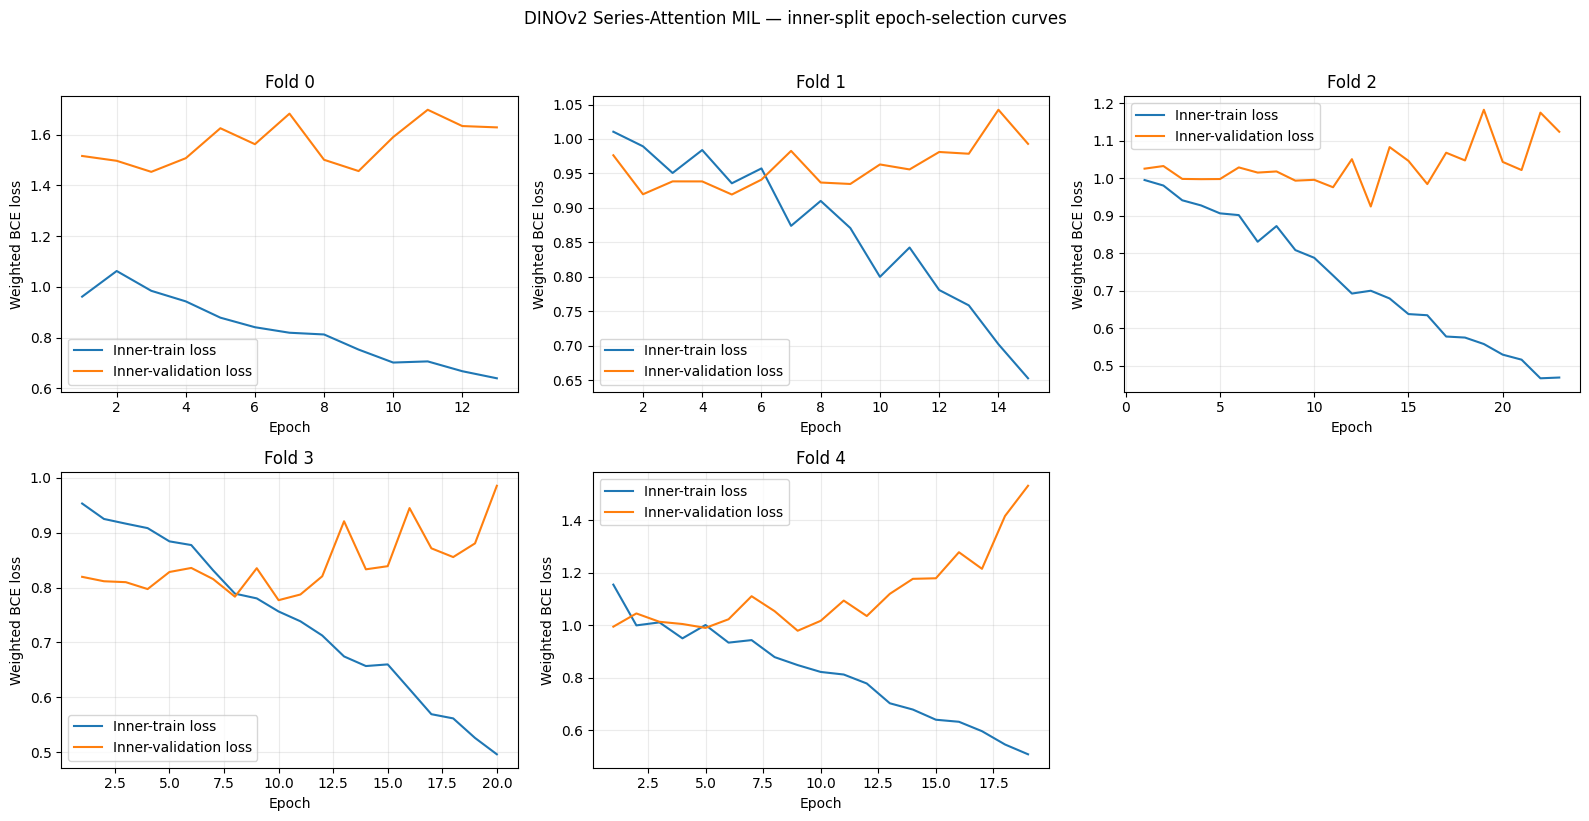

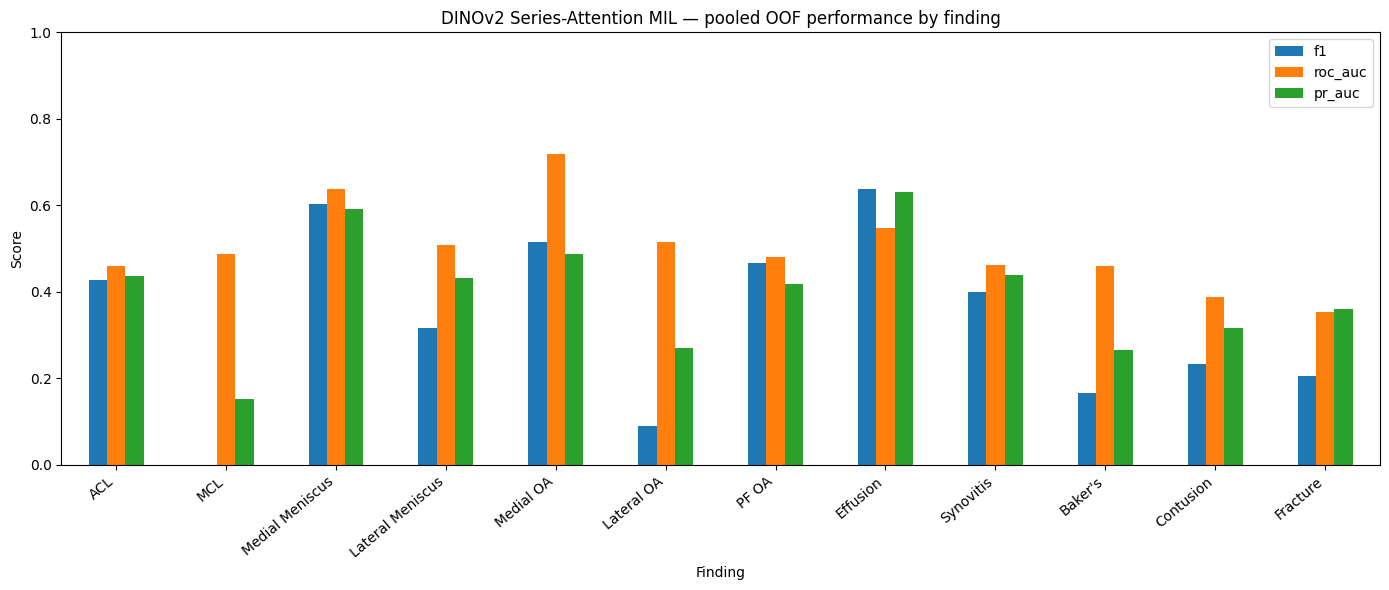

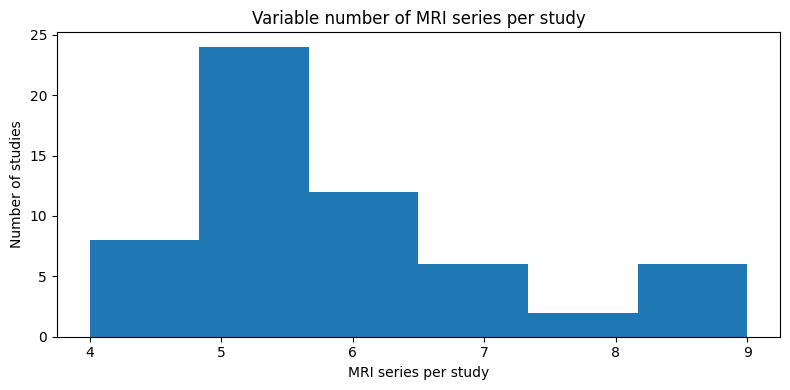

Saved: /kaggle/working/dinov2_series_attention_learning_curves.png
Saved: /kaggle/working/dinov2_series_attention_oof_per_class_metrics.png
Saved: /kaggle/working/dinov2_series_attention_series_count_distribution.png


In [13]:
# Inner-split learning curves, one panel per outer fold.
fig, axes = plt.subplots(2, 3, figsize=(16, 8), sharex=False, sharey=False)
axes = axes.flatten()
for fold in range(N_FOLDS):
    ax = axes[fold]
    fold_hist = all_history_df[all_history_df["fold"] == fold]
    ax.plot(fold_hist["epoch"], fold_hist["train_loss"], label="Inner-train loss")
    ax.plot(fold_hist["epoch"], fold_hist["val_loss"], label="Inner-validation loss")
    ax.set_title(f"Fold {fold}")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Weighted BCE loss")
    ax.grid(alpha=0.25)
    ax.legend()
axes[-1].axis("off")
fig.suptitle(
    "DINOv2 Series-Attention MIL — inner-split epoch-selection curves",
    y=1.02,
)
fig.tight_layout()
learning_curve_path = os.path.join(OUTPUT_DIR, f"{BASE}_learning_curves.png")
fig.savefig(learning_curve_path, dpi=160, bbox_inches="tight")
plt.show()

# Pooled OOF per-finding metrics.
plot_metrics = per_class_df.set_index("label")[["f1", "roc_auc", "pr_auc"]]
ax = plot_metrics.plot(kind="bar", figsize=(14, 6))
ax.set_title("DINOv2 Series-Attention MIL — pooled OOF performance by finding")
ax.set_xlabel("Finding")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
plt.xticks(rotation=40, ha="right")
plt.tight_layout()
per_class_plot_path = os.path.join(OUTPUT_DIR, f"{BASE}_oof_per_class_metrics.png")
plt.savefig(per_class_plot_path, dpi=160, bbox_inches="tight")
plt.show()

# Series count per study, to show the variable-length bag structure.
series_counts = series_metadata.groupby("StudyInstanceUID").size()
plt.figure(figsize=(8, 4))
plt.hist(series_counts.to_numpy(), bins=min(15, max(5, int(series_counts.nunique()))))
plt.xlabel("MRI series per study")
plt.ylabel("Number of studies")
plt.title("Variable number of MRI series per study")
plt.tight_layout()
series_count_plot_path = os.path.join(OUTPUT_DIR, f"{BASE}_series_count_distribution.png")
plt.savefig(series_count_plot_path, dpi=160, bbox_inches="tight")
plt.show()

print("Saved:", learning_curve_path)
print("Saved:", per_class_plot_path)
print("Saved:", series_count_plot_path)

## 14. Inspect the highest-attention series in one held-out study

This is a diagnostic display of learned series weights. It is **not** a pixel-level explanation or a clinical interpretation.

Example held-out study: 1.2.826.0.1.3680043.8.498.29764868091238287072166823522853419550


,StudyInstanceUID,SeriesInstanceUID,Anatomical_Plane,Fluid_Sensitive,Fat_Suppression,Num_2p5D_Instances,attention_weight
157,1.2.826.0.1.3680043.8.498.29764868091238287072...,1.2.826.0.1.3680043.8.498.77755509181820937582...,Sagittal,0,0,35,9.999999e-01
158,1.2.826.0.1.3680043.8.498.29764868091238287072...,1.2.826.0.1.3680043.8.498.10554209211078193916...,Sagittal,1,1,35,1.679346e-07
159,1.2.826.0.1.3680043.8.498.29764868091238287072...,1.2.826.0.1.3680043.8.498.93049579888925063520...,Coronal,1,1,30,9.333773e-10
160,1.2.826.0.1.3680043.8.498.29764868091238287072...,1.2.826.0.1.3680043.8.498.92228187778325854441...,Axial,1,1,30,8.542802e-13


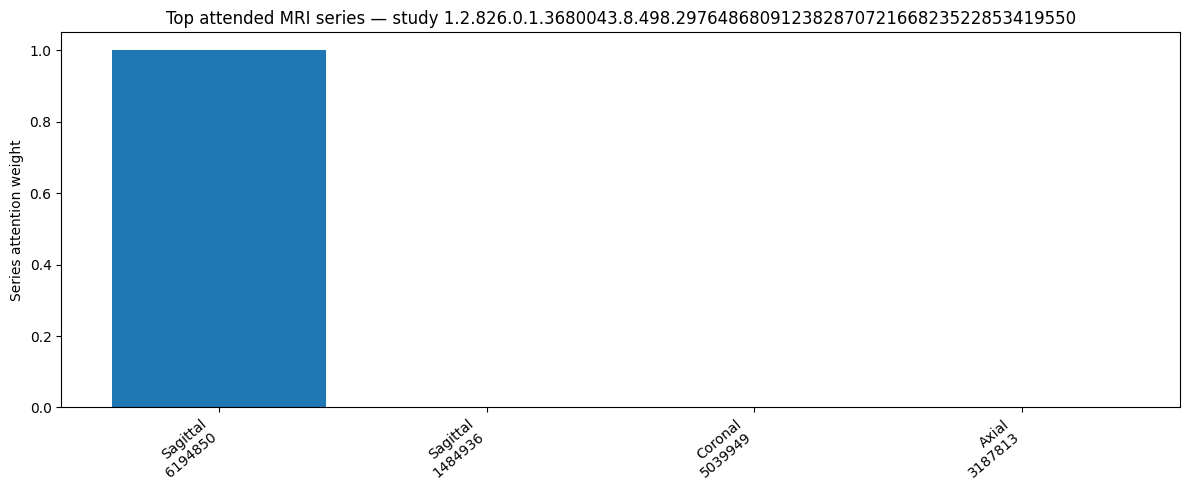

Saved: /kaggle/working/dinov2_series_attention_top_attention_example.png


In [14]:
example_study = (
    attention_weights_df.groupby("StudyInstanceUID")["attention_weight"]
    .max().sort_values(ascending=False).index[0]
)
example_attention = (
    attention_weights_df[
        attention_weights_df["StudyInstanceUID"] == example_study
    ]
    .sort_values("attention_weight", ascending=False)
    .head(15)
    .copy()
)

print("Example held-out study:", example_study)
cols_show = [c for c in [
    "StudyInstanceUID", "SeriesInstanceUID", "Anatomical_Plane",
    "Fluid_Sensitive", "Fat_Suppression", "Num_2p5D_Instances",
    "attention_weight"
] if c in example_attention.columns]
display(example_attention[cols_show])

labels_for_plot = []
for _, row in example_attention.iterrows():
    series_short = str(row["SeriesInstanceUID"])[-7:]
    plane = str(row.get("Anatomical_Plane", "series"))
    labels_for_plot.append(f"{plane}\n{series_short}")

plt.figure(figsize=(12, 5))
plt.bar(range(len(example_attention)), example_attention["attention_weight"].to_numpy())
plt.xticks(range(len(example_attention)), labels_for_plot, rotation=40, ha="right")
plt.ylabel("Series attention weight")
plt.title(f"Top attended MRI series — study {example_study}")
plt.tight_layout()
attention_plot_path = os.path.join(OUTPUT_DIR, f"{BASE}_top_attention_example.png")
plt.savefig(attention_plot_path, dpi=160, bbox_inches="tight")
plt.show()
print("Saved:", attention_plot_path)

## 15. Optional comparison against Notebooks 07, 08 and 10

Attach the saved output(s) from those notebooks if you want a combined comparison table. These inputs are optional and do not affect Notebook 11 training.

In [15]:
def find_input_artifacts(filename):
    matches = []
    base = "/kaggle/input"
    if not os.path.exists(base):
        return matches
    for current, dirs, files in os.walk(base):
        dirs[:] = [d for d in dirs if d not in PRUNE_DIRS]
        if filename in files:
            matches.append(os.path.join(current, filename))
    return sorted(set(matches))


comparison_frames = []
missing_comparison_models = []
previous_model_artifacts = [
    ("EfficientNet-B0", "efficientnet_b0_comparison_row.csv"),
    ("ViT-S/16", "vit_s16_comparison_row.csv"),
    ("DINOv2 slice-attention MIL", "dinov2_slice_attention_comparison_row.csv"),
]

for model_name, filename in previous_model_artifacts:
    paths = find_input_artifacts(filename)
    if not paths:
        missing_comparison_models.append(model_name)
        print(f"NOT FOUND: {filename}. Attach the corresponding saved notebook output if needed.")
        continue
    if len(paths) > 1:
        missing_comparison_models.append(model_name)
        print(f"AMBIGUOUS: multiple copies of {filename} were found:")
        for path in paths[:8]:
            print("  -", path)
        print("Attach only the intended/latest output copy.")
        continue

    path = paths[0]
    try:
        frame = pd.read_csv(path)
        if frame.empty or "model" not in frame.columns:
            raise ValueError("Comparison CSV must be non-empty and contain a 'model' column.")
        comparison_frames.append(frame)
        print(f"Loaded {model_name} comparison artifact: {path}")
    except Exception as exc:
        missing_comparison_models.append(model_name)
        print(f"Could not read {model_name} artifact {path}: {exc}")

# This notebook's own row is read from its known output path.
if os.path.exists(comparison_path):
    own_row = pd.read_csv(comparison_path)
    if not own_row.empty and "model" in own_row.columns:
        comparison_frames.append(own_row)
        print("Loaded current Notebook 11 comparison row:", comparison_path)
    else:
        print("Notebook 11 comparison row has an invalid format:", comparison_path)
else:
    print("Notebook 11 comparison row not found. Run Section 10 first:", comparison_path)

if comparison_frames:
    comparison_table = pd.concat(comparison_frames, ignore_index=True, sort=False)
    comparison_table = comparison_table.drop_duplicates(subset=["model"], keep="last")
    display(comparison_table)
else:
    print("No valid comparison rows were available.")

if missing_comparison_models:
    print(
        "\nCOMPARISON INCOMPLETE — missing or ambiguous rows: "
        + ", ".join(missing_comparison_models)
    )
    print(
        "Do not report this as a complete four-model comparison until all intended rows "
        "are attached. Notebook 11 training/evaluation is independent of these optional inputs."
    )
else:
    print("All four model rows are present. Verify metric definitions and evaluation protocols before reporting.")

Loaded EfficientNet-B0 comparison artifact: /kaggle/input/notebooks/minnieg12/07-efficientnet/efficientnet_b0_comparison_row.csv
Loaded ViT-S/16 comparison artifact: /kaggle/input/notebooks/minnieg12/08-vit/vit_s16_comparison_row.csv
Loaded DINOv2 slice-attention MIL comparison artifact: /kaggle/input/notebooks/minnieg12/10-slice-mil/dinov2_slice_attention_comparison_row.csv
Loaded current Notebook 11 comparison row: /kaggle/working/dinov2_series_attention_comparison_row.csv


,model,input,aggregation,loss,threshold,folds_completed,macro_auc_mean,macro_auc_std,macro_pr_auc_mean,macro_pr_auc_std,...,macro_precision,macro_recall,macro_f1,macro_specificity,micro_f1,hamming_loss,subset_accuracy,n_gold_studies,n_folds,n_series
0,EfficientNet-B0,2.5D previous/current/next slices,mean instance-logit pooling,weighted BCE,0.5,5.0,0.535003,0.059622,0.523504,0.067369,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,ViT-S/16,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.287907,0.296925,0.257234,0.748228,0.401413,0.365278,0.000000,NaN,NaN,NaN
2,DINOv2 ViT-S/14 + flat slice-attention MIL,NaN,NaN,NaN,0.5,NaN,NaN,NaN,NaN,NaN,...,0.317302,0.372480,0.278984,0.685667,0.401245,0.400253,0.000000,58.0,5.0,NaN
3,DINOv2 ViT-S/14 + series-attention MIL (mean s...,NaN,NaN,NaN,0.5,NaN,NaN,NaN,NaN,NaN,...,0.281753,0.393790,0.294843,0.624297,0.399394,0.445076,0.018182,58.0,5.0,336.0


All four model rows are present. Verify metric definitions and evaluation protocols before reporting.


## 16. Final artifact checklist and interpretation notes

In [16]:
expected_outputs = [
    f"{BASE}_fold_results.csv",
    f"{BASE}_oof_predictions.csv",
    f"{BASE}_metric_summary.csv",
    f"{BASE}_comparison_row.csv",
    f"{BASE}_all_history.csv",
    f"{BASE}_oof_per_class_metrics.csv",
    f"{BASE}_oof_error_analysis.csv",
    f"{BASE}_oof_series_attention_weights.csv",
    f"{BASE}_series_embeddings_float32.npy",
    f"{BASE}_series_metadata.csv",
    f"{BASE}_learning_curves.png",
    f"{BASE}_oof_per_class_metrics.png",
    f"{BASE}_series_count_distribution.png",
    f"{BASE}_top_attention_example.png",
]
expected_outputs.extend([
    f"{BASE}_fold_{fold}.pth" for fold in range(N_FOLDS)
])

print("Notebook 11 output checklist:")
missing_outputs = []
for name in expected_outputs:
    path = os.path.join(OUTPUT_DIR, name)
    exists = os.path.exists(path)
    print(("OK   " if exists else "MISS ") + name)
    if not exists:
        missing_outputs.append(name)

print("\nFinal study-level OOF metric summary:")
display(metric_summary_df)

print("\nIntegrity summary:")
print("Gold studies:", len(oof_predictions_df))
print("MRI series:", len(attention_weights_df))
print("Series-attention records:", len(attention_weights_df))
print("OOF studies with attention:", attention_weights_df["StudyInstanceUID"].nunique())
print("Per-study attention sums to 1:", bool(np.allclose(attention_sum_check.to_numpy(), 1.0, atol=1e-4)))
print("Missing output artifacts:", missing_outputs)

print("\nImportant interpretation notes:")
print("1. Each MRI series is represented by the arithmetic mean of its DINOv2 2.5D-instance embeddings.")
print("2. Learned gated attention is applied across series within each study.")
print("3. Epoch selection uses an inner split; the outer held-out fold is evaluated after refitting.")
print("4. Splits are study-level and preserve the fold assignments from Notebook 05 / Notebook 09.")
print("5. The classification threshold is fixed at 0.50.")
print("6. Series-attention weights are model aggregation weights, not pixel-level saliency or clinical explanations.")
print("7. Notebook 12 will combine learned slice attention within each series with series attention across the study.")
print("8. Disclose external code/LLM assistance according to the course academic-integrity requirements.")

if missing_outputs:
    raise RuntimeError("One or more expected Notebook 11 artifacts are missing.")
print("\nNotebook 11 series-attention MIL pipeline completed successfully.")

Notebook 11 output checklist:
OK   dinov2_series_attention_fold_results.csv
OK   dinov2_series_attention_oof_predictions.csv
OK   dinov2_series_attention_metric_summary.csv
OK   dinov2_series_attention_comparison_row.csv
OK   dinov2_series_attention_all_history.csv
OK   dinov2_series_attention_oof_per_class_metrics.csv
OK   dinov2_series_attention_oof_error_analysis.csv
OK   dinov2_series_attention_oof_series_attention_weights.csv
OK   dinov2_series_attention_series_embeddings_float32.npy
OK   dinov2_series_attention_series_metadata.csv
OK   dinov2_series_attention_learning_curves.png
OK   dinov2_series_attention_oof_per_class_metrics.png
OK   dinov2_series_attention_series_count_distribution.png
OK   dinov2_series_attention_top_attention_example.png
OK   dinov2_series_attention_fold_0.pth
OK   dinov2_series_attention_fold_1.pth
OK   dinov2_series_attention_fold_2.pth
OK   dinov2_series_attention_fold_3.pth
OK   dinov2_series_attention_fold_4.pth

Final study-level OOF metric summary:


,metric,mean,std
0,macro_auc,0.554851,0.065297
1,macro_pr_auc,0.539779,0.060449
2,macro_precision,0.281753,0.042154
3,macro_recall,0.393790,0.082948
4,macro_f1,0.294843,0.057074
5,macro_specificity,0.624297,0.111208
6,micro_f1,0.399394,0.037678
7,hamming_loss,0.445076,0.052072
8,subset_accuracy,0.018182,0.036364



Integrity summary:
Gold studies: 58
MRI series: 336
Series-attention records: 336
OOF studies with attention: 58
Per-study attention sums to 1: True
Missing output artifacts: []

Important interpretation notes:
1. Each MRI series is represented by the arithmetic mean of its DINOv2 2.5D-instance embeddings.
2. Learned gated attention is applied across series within each study.
3. Epoch selection uses an inner split; the outer held-out fold is evaluated after refitting.
4. Splits are study-level and preserve the fold assignments from Notebook 05 / Notebook 09.
5. The classification threshold is fixed at 0.50.
6. Series-attention weights are model aggregation weights, not pixel-level saliency or clinical explanations.
7. Notebook 12 will combine learned slice attention within each series with series attention across the study.
8. Disclose external code/LLM assistance according to the course academic-integrity requirements.

Notebook 11 series-attention MIL pipeline completed successfully